# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

### Теоретичні питання

1. У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.

Модель не бачить літер: токенайзер ділить "трансформер" на підслова, кожне для моделі один id. Літери вона пригадує з навчання. Міркування не допомагають, бо спершу модель розписує слово по літерах теж по памʼяті і помиляється: без міркувань "транс" + "формер" → 1 "р"; з міркуваннями розписала т,р,а,н,с,т,о,м,е,р → 2.


In [1]:
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

word = "трансформер"
ids = tokenizer(word, add_special_tokens=False)["input_ids"]
pieces = [tokenizer.decode([i]) for i in ids]

print("токени:", pieces)
print(f"{len(ids)} токенів проти {len(word)} літер")
print("«р» у кожному токені:", [(p, p.count("р")) for p in pieces])
print("правильна відповідь:", word.count("р"))

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

токени: ['т', 'ран', 'с', 'форм', 'ер']
5 токенів проти 11 літер
«р» у кожному токені: [('т', 0), ('ран', 1), ('с', 0), ('форм', 1), ('ер', 1)]
правильна відповідь: 3


2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?

fp16: PPL en 2.67, uk 2.40, chrF 55.22, BLEU 23.71. int8: 2.67 / 2.40 / 58.25 / 26.17. int4: 2.81 / 2.76 / 55.34 / 29.79. int2: 60091 / 34451480 / 0.19 / 0.12. До int4 зміни малі. Найбільший стрибок між int4 і int2: перплексія зростає в ~21 000 (en) і ~12 000 000 (uk) разів, переклад зникає.

3. Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».

Ні. На int4 en +5%, uk +15%; на int2 uk у ~570 разів гірша. Це відповідає загальному висновку, що мови, менш представлені в навчанні, просідають першими.

4. Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?

Я обрав fp16 один раз, int4 двічі, однаково двічі (запити 3 і 5). Це збіглося з метриками: вони показали, що int4 майже не відрізняється від fp16 (chrF 55.34 проти 55.22), і стабільної переваги fp16 я не побачив. Різниця була лише в українських запитах (1, 2, 4), в англійських (3, 5) її не було. Це узгоджується з перплексією (+15% для української проти +5% для англійської). Але різниця йшла в різні боки, тож це радше випадкові відмінності відповідей, ніж помітне погіршення.

5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?

"The meeting has been moved to Thursday at three o’clock". Еталон: "Зустріч перенесли на четвер на третю годину". fp16: "Зустріч була перенесена на четвер, о 15 годин". За змістом правильно, але інші слова. Бали: BLEU 9.98, chrF 49.88. BLEU рахує збіги цілих слів, тому замінені слова сильно його знижують. chrF рахує символьні n-грами, тож спільні корені й закінчення дають частковий кредит і він вищий.

6. У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?

Памʼять: 8.04 → 4.42 → 2.73 → 1.81 GB, тобто у 1.82 / 2.95 / 4.44 раза. Не 2/4/8, бо ембединги (≈ 0.78 GB) лишаються в fp16 і додаються scale/zero-point. Швидкість не зросла, а впала: 16.34 → 6.15 → 3.00 → 3.06 tok/s, бо на T4 розпаковка ваг іде на чистому PyTorch. Тут квантизація економить памʼять, а не час.

7. Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.

Base-модель лише продовжує текст, на інструкціях її не донавчали, а «Яка столиця Франції?» схоже на початок списку питань вікторини.

8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?

Без міркувань 252 токени і 2.1 с, з міркуваннями 569 токенів і 4.8 с: приблизно у 2.3 раза більше. Міркує англійською, бо ланцюжки міркувань у навчальних даних переважно англійські.

9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.

Я перевірив кілька задач, але не знайшов такої, де режим міркування дає правильну відповідь, а без нього модель помиляється.

10. У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?

Для відтворюваності: temperature 0 дає жадібне декодування без випадковості, seed фіксує генератор. Тоді різниця між запусками залежить від досліджуваного фактора, а не від семплінгу.

11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?

На T4 get_device_capability() повертає (7, 5). Апаратний bf16 є з Ampere (8.0+), а fp16 T4 підтримує апаратно, тому використовуємо fp16.

12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.

≈ 4.02 млрд параметрів, fp16: 4.02·10⁹ × 2 ≈ 8.04 GB. У таблиці 2.4 теж 8.04 GB, тобто збіг: колонка показує памʼять ваг. Із множником 1.3 було б ≈ 10.4 GB. Підрахунок кодом: sum(p.numel() for p in model.parameters()).

13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.

Перплексія це exp(середня помилка передбачення наступного токена), тобто «між скількома токенами вагається модель». Між мовами порівнювати не можна: токенайзер ріже їх по-різному, тому uk PPL (2.40) нижча за en (2.67), хоча модель українською слабша. На осмисленому тексті PPL 2.67, на тих самих словах у випадковому порядку 391.5 (у ≈ 146 разів більше), бо без звʼязності наступне слово непередбачуване.

14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?

Пік більший на майже сталі ≈ 0.6 GB для всіх варіантів (8.64 − 8.04, 5.01 − 4.42 тощо). Це не ваги, а KV-кеш (144 KiB на токен), активації, логіти (словник 151 936 × довжина, у perplexity ще в float32) і тимчасові буфери.

15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?

fp16 краща 1 раз, int4 краща 2 рази, однаково 2 рази. З 5 порівнянь надійного висновку зробити не можна: навіть 5:0 дає p ≈ 0.06 (> 0.05). Для надійного висновку потрібно ≈ 50 порівнянь для переваги 70/30 і ≈ 200 для 60/40.

16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?

int2: випадкові токени й символи, зациклення, змішування мов, відповідь не повʼязана із запитом, chrF 0.19. В int4 ознаки вже є, але тонкі: вигадка, неточні слова, коротші відповіді.

17. Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.

Так, квантизація б'є по меншій моделі сильніше. На int4 перплексія Qwen3-1.7B зростає на 73% (en: 4.35 → 7.52) і 81% (uk: 3.10 → 5.60), а в 4B лише на 5% і 15%. Вже на int8 у 1.7B видно невелике зростання (en 4.35 → 4.45), у 4B його не було. Причина: менша модель має менше надлишкових параметрів, тому втрата точності ваг для неї відчутніша. int2 руйнує обидві (PPL en 438 691 проти 60 092). chrF для 1.7B не порівнюваний: у генерації був увімкнений режим міркування, тож переклади обрізались (chrF 8.64 проти 55.22 у 4B).

18. Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?

OLLAMA_NUM_PARALLEL задає, скільки запитів модель обробляє одночасно, кожен зі своїм KV-кешем, у одному батчі.

19. Чому майже всі сучасні моделі зберігаються в bf16?

bf16 має діапазон як fp32 при розмірі 2 байти, а fp16 переповнюється вище 65 504. Не треба loss scaling, конвертація з fp32 тривіальна, апаратна підтримка. Моделі тренують у bf16, тож і зберігають у ньому без втрат на конвертацію.

20. Чому майже всі сучасні моделі зберігаються в bf16?
Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

OpenAI першою зробила масове чат-API, ChatGPT зробив його стандартом, і навколо виросла вся екосистема.

## Залізо  
i7-8700K  
RTX 3070 8GB VRAM  
16GB DDR4 2666MHz RAM

## Розрахунок

RTX 3070 bandwidth = 448 GB/s

1.7B y int4: 1.7 * 0.5 * 1.3 ≈ 1.1 | 448 / 0.85 ≈ 527  
4B y int4: 4 * 0.5 * 1.3 ≈ 2.6 | 448 / 2 ≈ 224  
8B y int4: 8 * 0.5 * 1.3 ≈ 5.2 | 448 / 4 ≈ 112  
14B y int4: 14 * 0.5 * 1.3 ≈ 9.1 | 448 / 7 ≈ 64  

1.7B y FP8: 1.7 * 1 * 1.3 ≈ 2.2 | 448 / 1.7 ≈ 264  
4B y FP8: 4 * 1 * 1.3 ≈ 5.2 | 448 / 4 ≈ 112  
8B y FP8: 8 * 1 * 1.3 ≈ 10.4 | 448 / 8 ≈ 56  
14B y FP8: 14 * 1 * 1.3 ≈ 18.2 | 448 / 14 ≈ 32  

1.7B y int8: 1.7 * 1 * 1.3 ≈ 2.2 | 448 / 1.7 ≈ 264  
4B y int8: 4 * 1 * 1.3 ≈ 5.2 | 448 / 4 ≈ 112  
8B y int8: 8 * 1 * 1.3 ≈ 10.4 | 448 / 8 ≈ 56  
14B y int8: 14 * 1 * 1.3 ≈ 18.2 | 448 / 14 ≈ 32  

1.7B y FP16: 1.7 * 2 * 1.3 ≈ 4.4 | 448 / 3.4 ≈ 132  
4B y FP16: 4 * 2 * 1.3 ≈ 10.4 | 448 / 8 ≈ 56  
8B y FP16: 8 * 2 * 1.3 ≈ 20.8 | 448 / 16 ≈ 28  
14B y FP16: 14 * 2 * 1.3 ≈ 36.4 | 448 / 28 ≈ 16  

1.7B y BF16: 1.7 * 2 * 1.3 ≈ 4.4 | 448 / 3.4 ≈ 132  
4B y BF16: 4 * 2 * 1.3 ≈ 10.4 | 448 / 8 ≈ 56  
8B y BF16: 8 * 2 * 1.3 ≈ 20.8 | 448 / 16 ≈ 28  
14B y BF16: 14 * 2 * 1.3 ≈ 36.4 | 448 / 28 ≈ 16  

## Вибір моделі й рантайму

Як рантайм обрано Ollama. Вона працює на Windows, macOS і Linux, не потребує складного налаштування, а модель завантажується однією командою.

Обрано квантизовану версію Qwen3-8B тому що це найбільша модель, яка повністю вміщається у 8 GB.

## Вимірювання

Розрахунок памʼяті: ваги Qwen3 8B ≈ 5,2 GB + KV-кеш на 4096 токенів (144 KiB × 4096 ≈ 0,6 GiB) ≈ 5,6–5,8 GB.

Виміряно: ollama ps показує 5,6 GB, 100% GPU, контекст 4096. nvidia-smi показує, що процес llama-server займає 5530 MiB.

Висновок: оцінка памʼяті збіглася з вимірюванням, модель повністю вміщається у VRAM із запасом ≈ 1,8 GiB.

Швидкість: розрахункова стеля 448 GB/s / ≈ 5,2 GB ≈ 86 tok/s. Виміряно (1 клієнт) ≈ 71 tok/s, тобто ≈ 83% від стелі, що відповідає типовим 60–90%.

[lab4/demo/screenshots/qwen3-8b/bench-results.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/bench-results.jpg)

[nvidia-smi](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/nvidia-smi.jpg)

### Власні промпти:

#### 1. What is the capital of Ukraine?  

The capital of Ukraine is **Kyiv** (also spelled Kyiv or Kiev). It is the largest city in Ukraine and serves as the country's political, economic, and cultural center.

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-1.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-1.jpg)

#### 2. What colors make up the flag of France?  

The flag of France consists of three vertical stripes of equal width:

- **Blue** on the left
- **White** in the middle
- **Red** on the right

These colors are known as the **Tricolore** and symbolize liberty, equality, and fraternity.

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-2.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-2.jpg)

#### 3. Яка найдовша річка, що протікає в Україні?  

Найдовшою річкою, що протікає в Україні, є **Дніпро**. Його загальна довжина становить **2285 км**. Дніпро протікає через кілька регіонів України, включаючи Дніпропетровську, Харківську, Одеську та Донецьку області, і є головною річкою України. Він відокремлюється від Дунайського водного русла на межі з Росією, а в межах України він впадає в Каспійське море.

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-3.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-3.jpg)

#### 4. Хто написав збірку «Кобзар»?

Збірку «Кобзар» написав український поет **Тарас Шевченко**. Це одна з найвідоміших і найважливіших поетичних збірок в українській літературі. Вона була опублікована в 1840 році і містить багато творів, які відображають теми національної ідеї, свободи, любові та соціальної правди.

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-4.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-4.jpg)

#### 5. Скільки разів літера «р» трапляється в слові «трансформер»?

Розглянемо слово **«трансформер»**.

Розкладемо його на окремі літери:

**т р а н с ф о р м е р**

Тепер підрахуємо, скільки разів зустрічається літера **«р»**:

1. **р** — 1 раз
2. **р** — 2 раз
3. **р** — 3 раз

Отже, літера **«р»** зустрічається **3 рази**.

**Відповідь: 3.**

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-5.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-5.jpg)

#### 6. What is 17 multiplied by 24?

To find $ 17 \times 24 $, you can break it down:

$$
17 \times 24 = 17 \times (20 + 4) = (17 \times 20) + (17 \times 4)
$$

$$
17 \times 20 = 340
$$
$$
17 \times 4 = 68
$$

Now add them together:

$$
340 + 68 = 408
$$

So, $ 17 \times 24 = \boxed{408} $.

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-6.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-6.jpg)

#### 7. A train leaves at 14:15 and the trip takes 2 hours 50 minutes. At what time does it arrive?

To find the arrival time, we add the travel time to the departure time.

**Departure time:** 14:15
**Travel time:** 2 hours 50 minutes

### Step 1: Add the hours
14:15 + 2 hours = **16:15**

### Step 2: Add the minutes
16:15 + 50 minutes = **17:05**

### ✅ Final Answer: **17:05** (or **5:05 PM**)

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-7.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-7.jpg)

#### 8. Explain in two sentences why the sky is blue.

The sky appears blue because sunlight interacts with the gases and particles in Earth's atmosphere, scattering shorter wavelengths of light, like blue, more effectively than longer wavelengths. This scattered blue light is what we see when we look up at the sky on a clear day.

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-8.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-8.jpg)

#### 9. Return only a JSON object with the keys "country" and "capital" for Japan.

{"country": "Japan", "capital": "Tokyo"}

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-9.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-9.jpg)

#### 10. Translate into Ukrainian: The meeting has been moved to Thursday.

Зустріч переміщена на четвер.

Скріншот: [lab4/demo/screenshots/qwen3:8b/prompt-10.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-8b/prompt-10.jpg)

## Оптимізація

Після зміни моделі з Qwen3 8B на Qwen3 4B швидкість генерації для одного користувача зросла з 73,2 до 119,7 tok/s, що становить ≈ 70% від розрахункової стелі 448 GB/s / ≈ 2,6 GB ≈ 172 tok/s. Памʼять процесу llama-server зменшилася з 5530 до 3218 MiB.

Для застосунку я обрав qwen3:4b: він швидший, займає менше VRAM і достатньо точний для типових запитів застосунку.

[lab4/demo/screenshots/qwen3-4b/bench-results.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/bench-results.jpg)

[lab4/bench_results.csv](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/bench_results.csv)

[nvidia-smi](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/nvidia-smi.jpg)

### Власні промпти:

#### 1. What is the capital of Ukraine?

The capital of Ukraine is Kyiv.

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-1.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-1.jpg)

#### 2. What colors make up the flag of France?

The flag of France is made up of three colors: blue, white, and red. These colors are arranged vertically in three equal vertical bands, with blue on the left, white in the center, and red on the right. This tricolor flag is known as the *Tricolore* and is a symbol of the French Republic.

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-2.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-2.jpg)

#### 3. Яка найдовша річка, що протікає в Україні?

Найдовша річка, що протікає в Україні, — **Дніпро**.

Він протікає через середню та південну частину України, проходячи через 11 відповідних областей, включаючи Київ, Харків, Дніпропетровськ, Орлов, Дніпропетровськ і інші.

**Довжина Дніпра** — близько **2200 км** (від джерела до моря).

Це найбільша річка в Україні не лише за довжиною, але й за впливом на економіку, транспорт і культуру країни.

✅ Отже, відповідь: **Дніпро**.

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-3.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-3.jpg)

#### 4. Хто написав збірку «Кобзар»?

Збірка «Кобзар» написана **Тарасом Шевченком**.

Це одна з найвідоміших та найвпливовіших поезій у українській літературі, яка була випущена в 1840-х роках. У «Кобзарі» Шевченко виражає глибоку любов до Батьківщини, розкриває проблеми соціальних нерівностей, боротьбу за свободу людини та високий естетичний рівень поезії.

«Кобзар» — це не просто поезійний цикл, а символічний образ — кобзар, який виконує народну музу, передає душу народу, його страждання, надію та бажання свободи.

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-4.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-4.jpg)

#### 5. Скільки разів літера «р» трапляється в слові «трансформер»?

Розглянемо слово **«трансформер»**.

Покажемо, як виглядає це слово буквою за буквою:

**т – р – а – н – с – ф – о – р – м – е – р**

Тепер порахуємо, скільки разів трапляється літера **«р»**.

- Перша «р» — на позиції 2 (після «т»)
- Друга «р» — на позиції 8 (після «ф»)
- Третя «р» — на позиції 11 (на кінці)

Отже, літера **«р»** трапляється **три** рази.

✅ **Відповідь: 3 рази.**

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-5.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-5.jpg)

#### 6. What is 17 multiplied by 24?

To find what 17 multiplied by 24 is, we can compute:

$$
17 \times 24
$$

We can break this down using the distributive property:

$$
17 \times 24 = 17 \times (20 + 4) = (17 \times 20) + (17 \times 4)
$$

Now calculate each part:

- $17 \times 20 = 340$
- $17 \times 4 = 68$

Add them together:

$$
340 + 68 = 408
$$

So, the final answer is:

$$
\boxed{408}
$$

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-6.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-6.jpg)

#### 7. A train leaves at 14:15 and the trip takes 2 hours 50 minutes. At what time does it arrive?

We are given:

- The train **leaves at 14:15**
- The **trip takes 2 hours 50 minutes**

We need to find the **arrival time**.

---

**Step 1: Add 2 hours to 14:15**

14:15 + 2 hours = **16:15**

---

**Step 2: Add 50 minutes to 16:15**

16:15 + 50 minutes = ?

Start with 16:15
Add 45 minutes → 17:00
Then add the remaining 5 minutes → 17:05

So, 16:15 + 50 minutes = **17:05**

---

✅ **Final Answer: 17:05**

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-7.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-7.jpg)

#### 8. Explain in two sentences why the sky is blue.

The sky appears blue because molecules in the atmosphere scatter shorter blue light waves more effectively than longer red light waves. This scattering, known as Rayleigh scattering, is most intense for blue light, so when sunlight enters the atmosphere, the blue wavelengths are scattered in all directions, making the sky appear blue during the day.

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-8.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-8.jpg)

#### 9. Return only a JSON object with the keys "country" and "capital" for Japan.

{"country": "Japan", "capital": "Tokyo"}

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-9.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-9.jpg)

#### 10. Translate into Ukrainian: The meeting has been moved to Thursday.

Зустріч пересунуто на четверте.

Скріншот: [lab4/demo/screenshots/qwen3:4b/prompt-10.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/qwen3-4b/prompt-10.jpg)

## Власний застосунок

[lab4/app/main.py](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/app/main.py)

[lab4/app/README.md](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/app/README.md)

## Перевірка та демонстрація

### Тестові сценарії

#### 1. Простий факт

What is the capital of Ukraine?

The capital of Ukraine is Kyiv.

Очікувано: Kyiv.  
Модель повернула правильну відповідь Kyiv.

Скріншот: [lab4/demo/screenshots/app/simple-fact.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/simple-fact.jpg)

#### 2. Памʼять діалогу

my name is Oleksii

Hello Oleksii! How can I help you today? ☺

what is my name?

Your name is Oleksii! ☺

Очікувано: у другому запиті модель називає імʼя з першого.  
Модель відповіла Oleksii.

Скріншот: [lab4/demo/screenshots/app/memory-test.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/memory-test.jpg)

#### 3. Команда /clear

my name is Oleksii → Hello Oleksii! How can I assist you today? ☺

what is my name? → Your name is Oleksii! ☺

/clear

History cleared.

what is my name?

I don't know your name. You'll have to tell me! ☺

Очікувано: після /clear модель імені не знає.  
Модель відповіла, що не знає імені.

Скріншот: [lab4/demo/screenshots/app/clear.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/clear.jpg)

#### 4. Українська мова

Хто написав збірку «Кобзар»?

Збірку «Кобзар» написав **Тарас Шевченко**.

Очікувано: Тарас Шевченко.  
Модель повернула правильну відповідь українською.  

Скріншот: [lab4/demo/screenshots/app/ukrainian.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/ukrainian.jpg)

#### 5. Складний випадок: підрахунок літер

How many times does the letter r appear in the word strawberry?

Let's go step by step: ... (модель перебирає літери по одній: s, t, r, a, w, b, e, r, y) ... That makes a total of 2 times. Final answer: 2  
Очікувано: 3 (st**r**awbe**rr**y). Модель відповіла 2 що є помилкою.

Скріншот: [lab4/demo/screenshots/app/letter-count.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/letter-count.jpg)

#### 6. Складний випадок: переклад

Translate into Ukrainian: The meeting has been moved to Thursday.

Зустріч перенесена на четверте.

Очікувано: Зустріч перенесено на четвер..  
Модель повернула на четверте: четверте — порядковий числівник, а не день тижня. Перше слово й структура речення правильні, але сенс спотворено.

Скріншот: [lab4/demo/screenshots/app/translation.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/translation.jpg)

#### 7. Крайовий випадок: сервер не запущено

obama balls

Error: Connection error.. Check that the server is running and the model name is correct.

Очікувано: програма не падає, а показує зрозумілу помилку й знову чекає ввід.  
Застосунок вивів повідомлення про помилку й повернувся до запрошення `>`.

Скріншот: [lab4/demo/screenshots/app/server-not-running.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/server-not-running.jpg)

### Помилки моделі

#### 1. Підрахунок літер у слові

How many times does the letter r appear in the word strawberry?

Відповідь qwen3-4b: модель розписала слово по літерах (s, t, r, a, w, b, e, r, y), знайшла дві літери r і дала фінальну відповідь 2.
Правильна відповідь — 3 (st**r**awbe**rr**y).

Де саме помилка: Модель не помилилась у самому лічильнику: вона порахувала правильно те, що перелічила. Помилка в перелічуванні: у списку 9 літер замість 10, друга літера r з подвійного rr випала.

Причина: Модель працює не з літерами, а з токенами. Окремих літер усередині токена модель не бачить, а відтворює їх із памʼяті, тож подвійні літери легко губляться. Це та сама причина, що й у розділі 1.5 демо-ноутбука.

Що я зробив: Подав слово моделі вже розбитим на частини: how many does does the letter r appear in the word st r abe rr y? Модель відповіла **3**, перелічивши літери s, t, r, a, b, e, r, r, y, і вказала позиції 3, 7 і 8.  

Скріншот: [lab4/demo/screenshots/app/letter-count-fixed.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/letter-count-fixed.jpg)

#### Помилка 2. Переклад речення українською

Запит: Translate into Ukrainian: The meeting has been moved to Thursday.

Відповідь qwen3:4b: Зустріч перенесена на четверте. Правильно: Зустріч перенесено на четвер. Перше слово й структура речення правильні, але четверте — порядковий числівник, а не день тижня, тож сенс спотворено.

Що я зробив: Замінив модель на qwen3-8b. Вона повернула правильний переклад: Зустріч переміщена на четвер.

Скріншот: [lab4/demo/screenshots/app/translation-fixed.jpg](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app/translation-fixed.jpg)

### Робота застосунку

#### Відео: [lab4/demo/video.mp4](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/video.mp4)
#### Скріншоти: [lab4/demo/screenshots/app/*](https://github.com/FearlessAtom/artificial-intelligence-systems/tree/main/lab4/demo/screenshots/app)

## Висновок

У роботі я запустив мовні моделі локально через Ollama на 8 GB VRAM, 448 GB/s і підібрав модель під це залізо за розрахунком: Qwen3 8B у int4 найбільша модель, що повністю вміщається у VRAM. Розрахунок памʼяті збігся з вимірюванням, а виміряна швидкість 8B склала типові 60–90% від теоретичної стелі, бо генерація впирається в пропускну здатність памʼяті.

Для оптимізації я перейшов на Qwen3 4B: швидкість зросла з 73,2 до 119,7 tok/s, а памʼять процесу зменшилась з 5530 до 3218 MiB. Ціною стала дещо нижча якість: на моїх 10 промптах 4B справлялась з простими фактами, арифметикою, JSON і підрахунком літер, але гірше переклала речення українською і додала неточності у відповідь про Дніпро. Для чат-застосунку з короткими запитами цього достатньо, тож для застосунку я обрав qwen3:4b: він швидший, залишає запас VRAM під довший контекст і дає відповідь майже миттєво.

Під час тестування застосунку я побачив типові обмеження малих моделей: помилки в підрахунку літер через токенізацію і неточний переклад. Підрахунок літер вдалося виправити, подавши слово вже розбитим на частини. Для складніших перекладів можна перемкнутися на 8B, жертвуючи швидкістю.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [2]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [3]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [4]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [5]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [6]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [7]:
QUESTION = "Яка столиця Франції?"

In [8]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [9]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [10]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.2 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 5.1 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [11]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 2.0 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 6.0 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [12]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [13]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [29]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [30]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [31]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True, enable_thinking=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [32]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,12.43,22.95,4.35,3.10,8.64,0.25
int8,2.04,2.98,13.50,4.45,3.11,9.13,0.25
int4,1.38,2.31,6.98,7.52,5.60,10.10,0.58
int2,1.03,1.96,6.95,438691.38,5951889.50,0.11,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

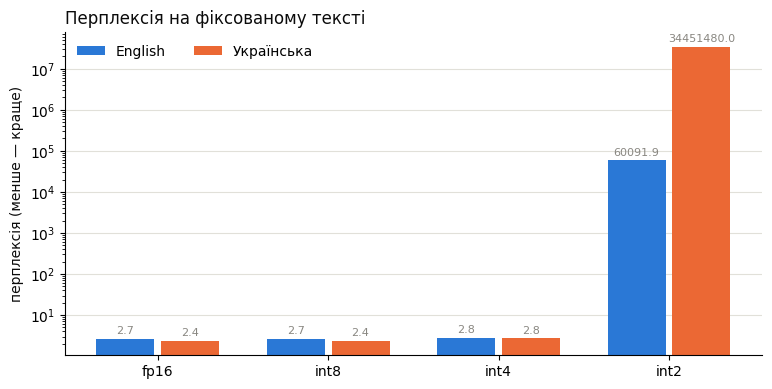

In [18]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [19]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [20]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [24]:
VOTES = {1: "A", 2: "B", 3: "=", 4: "A", 5: "="}

In [25]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,fp16
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,int4
2,Explain in three sentences why the sky is blue.,fp16,int4,однаково
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,int4
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 1, int4 краща: 2, однаково: 2


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [23]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -